In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

In [6]:
data_dir = "../../nfl-big-data-bowl-2027/nfl_big_bowl_dbt_data_storage/seeds/"
big_data_dir = "../../nfl-big-data-bowl-2027/nfl_big_bowl_large_files/"
player_csv = data_dir + "players.csv"
combine_csv = big_data_dir + "combine_tracking.csv"

In [7]:
player_csv = data_dir + "players.csv"
wr_pos = []
for chunk in pd.read_csv(player_csv, chunksize=400_000):
    selected = (
        chunk["nfl_position"] == "WR"
    )
    if selected.any():
        wr_pos.append(chunk.loc[selected].copy())
wide_receivers_df = pd.concat(wr_pos, ignore_index=True)
nfl_wr_id = set(wide_receivers_df["nfl_id"])
print(len(wide_receivers_df))
print(len(nfl_wr_id))
wide_receivers_df.head()


106
106


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55884,Jaxon Smith-Njigba,2023,WR,2002-02-14,Ohio State,Big Ten Conference,1.0,20.0,20.0
1,55885,Quentin Johnston,2023,WR,2001-09-06,Texas Christian,Big Twelve Conference,1.0,22.0,21.0
2,55887,Jordan Addison,2023,WR,2002-01-27,Southern California,Pacific Twelve Conference,1.0,24.0,23.0
3,55904,Jonathan Mingo,2023,WR,2001-04-20,Mississippi,Southeastern Conference,2.0,8.0,39.0
4,55915,Jayden Reed,2023,WR,2000-04-28,Michigan State,Big Ten Conference,2.0,19.0,50.0


In [8]:
track_parts = []
for chunk in pd.read_csv(combine_csv, chunksize=400_000):
    selected = (
        chunk.entity_type.eq("PLAYER")
        & (
            chunk.drill_type.eq("SKILL_DRILLS_WR")
            | chunk.drill_type.isin({
                "FORTY_YARD_DASH",
                "THREE_CONE_DRILL",
                "SHORT_SHUTTLE"
            })
        )
        & chunk.nfl_id.isin(nfl_wr_id)
    )
    if selected.any():
        track_parts.append(chunk.loc[selected].copy())

tracking = pd.concat(track_parts, ignore_index=True)
tracking.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02T00:45:26.700,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.754100,13.583463,0.624946,3.118189,0.001323,71.210353
1,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02T00:45:26.800,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.825478,13.606387,0.952825,3.584155,0.005122,70.563882
2,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02T00:45:26.900,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,24.937019,13.638515,1.339290,3.997314,0.012484,70.829717
3,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02T00:45:27.000,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,25.081548,13.689702,1.752842,4.333521,0.021052,70.606116
4,2025,20250301100800_1740876338472_000,58968,PLAYER,2025-03-02T00:45:27.100,SKILL_DRILLS_WR,POST_CORNER_ROUTE_RIGHT,15,25.270650,13.764353,2.215085,4.603238,0.036191,70.224139


In [9]:
wr_attempt = tracking.groupby(["nfl_id", "attempt", "drill_name"]).count().reset_index()
wr_attempt.head()

,nfl_id,attempt,drill_name,draft_year,event_id,entity_type,time,drill_type,x,y,s,a,dis,dir
0,55884,1,DAGGER_ROUTE_LEFT,64,64,64,64,64,64,64,64,64,64,64
1,55884,1,GAUNTLET_DRILL,89,89,89,89,89,89,89,89,89,89,89
2,55884,1,OVER_SHOULDER_ADJUST,56,56,56,56,56,56,56,56,56,56,56
3,55884,1,POST_CORNER_ROUTE_LEFT,52,52,52,52,52,52,52,52,52,52,52
4,55884,1,SLANT_ROUTE_LEFT,50,50,50,50,50,50,50,50,50,50,50


In [10]:
three_cone = wr_attempt[wr_attempt["drill_name"] == "THREE_CONE_DRILL"]
three_cone.head()

,nfl_id,attempt,drill_name,draft_year,event_id,entity_type,time,drill_type,x,y,s,a,dis,dir
194,55990,3,THREE_CONE_DRILL,84,84,84,84,84,84,84,84,84,84,84
308,56070,2,THREE_CONE_DRILL,75,75,75,75,75,75,75,75,75,75,75
325,56071,1,THREE_CONE_DRILL,74,74,74,74,74,74,74,74,74,74,74
443,56220,1,THREE_CONE_DRILL,76,76,76,76,76,76,76,76,76,76,76
486,56238,2,THREE_CONE_DRILL,76,76,76,76,76,76,76,76,76,76,76


In [11]:
tracking["drill_name"].unique()

array(['POST_CORNER_ROUTE_RIGHT', 'GAUNTLET_DRILL',
       'OVER_SHOULDER_ADJUST', 'GO_ROUTE_RIGHT', 'CIRCUS_ROUTE_LEFT',
       'SLANT_ROUTE_LEFT', 'SPEED_OUT_ROUTE_LEFT', 'CURL_ROUTE_RIGHT',
       'DAGGER_ROUTE_LEFT', 'SLOT_STRIKE_ROUTE_LEFT',
       'COMEBACK_ROUTE_RIGHT', 'SLOT_SAIL_ROUTE_RIGHT',
       'RED_ZONE_FADE_RIGHT', 'FORTY_YARD_DASH', 'THREE_CONE_DRILL',
       'SHORT_SHUTTLE', 'SPEED_OUT_LEFT', 'POST_CORNER_ROUTE_LEFT'],
      dtype=object)

In [12]:
total_wr = tracking.groupby(["nfl_id", "drill_name"]).count().reset_index()
print(total_wr)
print(total_wr["nfl_id"].nunique())

      nfl_id              drill_name  draft_year  event_id  entity_type  time  \
0      55884       DAGGER_ROUTE_LEFT          64        64           64    64   
1      55884          GAUNTLET_DRILL         179       179          179   179   
2      55884    OVER_SHOULDER_ADJUST          56        56           56    56   
3      55884  POST_CORNER_ROUTE_LEFT          52        52           52    52   
4      55884        SLANT_ROUTE_LEFT          50        50           50    50   
...      ...                     ...         ...       ...          ...   ...   
1455   59278     RED_ZONE_FADE_RIGHT          41        41           41    41   
1456   59278        SLANT_ROUTE_LEFT          28        28           28    28   
1457   59278   SLOT_SAIL_ROUTE_RIGHT          69        69           69    69   
1458   59278  SLOT_STRIKE_ROUTE_LEFT          65        65           65    65   
1459   59278    SPEED_OUT_ROUTE_LEFT          47        47           47    47   

      drill_type  attempt  

In [13]:
tracking.dtypes

draft_year       int64
event_id        object
nfl_id           int64
entity_type     object
time            object
drill_type      object
drill_name      object
attempt          int64
x              float64
y              float64
s              float64
a              float64
dis            float64
dir            float64
dtype: object

In [14]:
first_attempt = tracking[(tracking.nfl_id.eq(55884)) & (tracking.drill_name.eq("THREE_CONE_DRILL"))]
first_attempt.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir


In [15]:
first_attempt = tracking[tracking.nfl_id.eq(55884)]
first_attempt.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
93179,2023,6414e684e3d8e72dcdcb4ed7-2023,55884,PLAYER,2023-03-04T22:33:40.200,SKILL_DRILLS_WR,SLOT_STRIKE_ROUTE_LEFT,1,24.400000,35.266667,0.073333,0.504964,0.000000,2.602562
93180,2023,6414e684e3d8e72dcdcb4ed7-2023,55884,PLAYER,2023-03-04T22:33:40.300,SKILL_DRILLS_WR,SLOT_STRIKE_ROUTE_LEFT,1,24.400000,35.300000,0.200000,0.531089,0.001111,356.185925
93181,2023,6414e684e3d8e72dcdcb4ed7-2023,55884,PLAYER,2023-03-04T22:33:40.400,SKILL_DRILLS_WR,SLOT_STRIKE_ROUTE_LEFT,1,24.366667,35.333333,0.283333,0.838418,0.001571,357.978635
93182,2023,6414e684e3d8e72dcdcb4ed7-2023,55884,PLAYER,2023-03-04T22:33:40.500,SKILL_DRILLS_WR,SLOT_STRIKE_ROUTE_LEFT,1,24.366667,35.400000,0.320000,1.298888,0.004444,16.927513
93183,2023,6414e684e3d8e72dcdcb4ed7-2023,55884,PLAYER,2023-03-04T22:33:40.600,SKILL_DRILLS_WR,SLOT_STRIKE_ROUTE_LEFT,1,24.400000,35.433333,0.390000,1.865774,0.001571,36.674350


In [16]:
first_attempt.drill_name.unique()

array(['SLOT_STRIKE_ROUTE_LEFT', 'GAUNTLET_DRILL',
       'POST_CORNER_ROUTE_LEFT', 'DAGGER_ROUTE_LEFT',
       'SPEED_OUT_ROUTE_LEFT', 'SLANT_ROUTE_LEFT', 'OVER_SHOULDER_ADJUST'],
      dtype=object)

In [17]:
drills_list = ['POST_CORNER_ROUTE_RIGHT', 'GAUNTLET_DRILL',
       'OVER_SHOULDER_ADJUST', 'GO_ROUTE_RIGHT', 'CIRCUS_ROUTE_LEFT',
       'SLANT_ROUTE_LEFT', 'SPEED_OUT_ROUTE_LEFT', 'CURL_ROUTE_RIGHT',
       'DAGGER_ROUTE_LEFT', 'SLOT_STRIKE_ROUTE_LEFT',
       'COMEBACK_ROUTE_RIGHT', 'SLOT_SAIL_ROUTE_RIGHT',
       'RED_ZONE_FADE_RIGHT', 'FORTY_YARD_DASH', 'THREE_CONE_DRILL',
       'SHORT_SHUTTLE', 'SPEED_OUT_LEFT', 'POST_CORNER_ROUTE_LEFT']

def total_attempts(df: pd.DataFrame, drill: str, attempts: int):
    first = df[
        df.attempt.eq(attempts) &
        df.drill_name.eq(drill)
    ]
    total_count = first.nfl_id.nunique()
    print(f"{drill}: {total_count}")

for i in drills_list:
    total_attempts(tracking, i, 1)

POST_CORNER_ROUTE_RIGHT: 64
GAUNTLET_DRILL: 69
OVER_SHOULDER_ADJUST: 98
GO_ROUTE_RIGHT: 62
CIRCUS_ROUTE_LEFT: 0
SLANT_ROUTE_LEFT: 69
SPEED_OUT_ROUTE_LEFT: 38
CURL_ROUTE_RIGHT: 66
DAGGER_ROUTE_LEFT: 64
SLOT_STRIKE_ROUTE_LEFT: 62
COMEBACK_ROUTE_RIGHT: 60
SLOT_SAIL_ROUTE_RIGHT: 62
RED_ZONE_FADE_RIGHT: 64
FORTY_YARD_DASH: 87
THREE_CONE_DRILL: 16
SHORT_SHUTTLE: 16
SPEED_OUT_LEFT: 31
POST_CORNER_ROUTE_LEFT: 69


In [18]:
dagger_route = tracking[(tracking.drill_name.eq("DAGGER_ROUTE_LEFT") & 
                tracking.attempt.eq(1))]
dagger_route.head()


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
38610,2024,20240302100700_1709413970436_000,57606,PLAYER,2024-03-02T21:12:42.100,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,24.866667,45.833333,0.723333,3.231864,0.004444,78.016031
38611,2024,20240302100700_1709413970436_000,57606,PLAYER,2024-03-02T21:12:42.200,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,24.933333,45.833333,1.070000,3.696077,0.004444,84.112186
38612,2024,20240302100700_1709413970436_000,57606,PLAYER,2024-03-02T21:12:42.300,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,25.066667,45.866667,1.466667,4.214283,0.017812,86.480547
38613,2024,20240302100700_1709413970436_000,57606,PLAYER,2024-03-02T21:12:42.400,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,25.233333,45.833333,1.910000,4.627619,0.027800,89.400066
38614,2024,20240302100700_1709413970436_000,57606,PLAYER,2024-03-02T21:12:42.500,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,25.466667,45.833333,2.403333,4.981166,0.054444,90.953517


In [19]:
def plot_player_path(df, nfl_id, drill_name=None, attempt=None, cmap="plasma"):
    p = df[df["nfl_id"] == nfl_id]
    if drill_name is not None:
        p = p[p["drill_name"] == drill_name]
    if attempt is not None:
        p = p[p["attempt"] == attempt]
    p = p.sort_values("time")

    x, y, s = p["x"].to_numpy(), p["y"].to_numpy(), p["s"].to_numpy()

    points = np.column_stack([x, y]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    lc = LineCollection(segments, cmap=cmap, norm=plt.Normalize(s.min(), s.max()))
    lc.set_array((s[:-1] + s[1:]) / 2) 
    lc.set_linewidth(3)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.add_collection(lc)
    ax.scatter(x[0], y[0], c="green", s=60, zorder=3, label="Start")
    ax.scatter(x[-1], y[-1], c="red", s=60, zorder=3, label="End")

    ax.set_xlim(x.min() - 1, x.max() + 1)
    ax.set_ylim(y.min() - 1, y.max() + 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Player {nfl_id} | {p['drill_name'].iloc[0]} | attempt {p['attempt'].iloc[0]}")
    ax.legend()
    fig.colorbar(lc, ax=ax).set_label("Speed")
    plt.tight_layout()
    plt.show()

In [20]:
def plot_speed_vs_distance(df, nfl_id, drill_name=None, attempt=None):
    p = df[df["nfl_id"] == nfl_id]
    if drill_name is not None:
        p = p[p["drill_name"] == drill_name]
    if attempt is not None:
        p = p[p["attempt"] == attempt]
    p = p.sort_values("time")

    dist = p["dis"].fillna(0).cumsum().to_numpy()

    speed = p["s"].to_numpy()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.set_ylim(0, 11)
    ax.set_xlim(0, 35)
    ax.plot(dist, speed, lw=2)
    ax.set_xlabel("Total distance traveled")
    ax.set_ylabel("Speed")
    ax.set_title(f"Player {nfl_id} | {p['drill_name'].iloc[0]} | attempt {p['attempt'].iloc[0]}")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [21]:
def speed_distance_auc(df, nfl_id, drill_name=None, attempt=None, max_dist=None):
    p = df[df["nfl_id"] == nfl_id]
    if drill_name is not None:
        p = p[p["drill_name"] == drill_name]
    if attempt is not None:
        p = p[p["attempt"] == attempt]
    p = p.sort_values("time")

    dist = np.r_[0, np.cumsum(np.hypot(np.diff(p["x"]), np.diff(p["y"])))]
    speed = p["s"].to_numpy()

    if max_dist is not None:
        m = dist <= max_dist
        dist, speed = dist[m], speed[m]

    trapz = getattr(np, "trapezoid", None) or np.trapz   
    auc = trapz(speed, dist)
    return {
        "auc": auc,                                  
        "total_dist": dist[-1],
        "avg_speed_over_dist": auc / dist[-1],       
    }

In [22]:
def route_running_plots(df, pid, route, attempt = 1):
    plot_player_path(df, pid, route, attempt)
    plot_speed_vs_distance(df, pid, route, attempt)
    info = speed_distance_auc(df, pid, route, attempt)
    for name, i in info.items():
        print(str(name) + ": " + str(i))

In [23]:
def resample_path(x, y, n=200):
    """Resample a path to n points evenly spaced by arc length."""
    d = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    t = np.linspace(0, d[-1], n)
    return np.column_stack([np.interp(t, d, x), np.interp(t, d, y)])

def mean_path(paths, method="arclength", n=200):
    """paths: list of (x, y) arrays. Returns (n, 2) average path and an (n,) spread."""
    R = np.array([resample_path(x, y, n) for x, y in paths])   # (runs, n, 2)

    if method == "arclength":
        mean = R.mean(axis=0)
    elif method == "dba":
        from tslearn.barycenters import dtw_barycenter_averaging
        mean = dtw_barycenter_averaging(R, max_iter=50)
    else:
        raise ValueError("method must be 'arclength' or 'dba'")

    spread = np.hypot(*(R - mean).transpose(2, 0, 1)).mean(axis=0)
    return mean, spread

def plot_player_paths_all(df, drill_name=None, attempt=None, alpha=0.35, cmap="turbo",
                          show_mean=True, method="arclength"):
    d = df if drill_name is None else df[df["drill_name"] == drill_name]

    if attempt is None:
        first = d.groupby("nfl_id")["attempt"].transform("min")
        d = d[d["attempt"] == first]
    else:
        d = d[d["attempt"] == attempt]

    ids = d["nfl_id"].unique()
    colors = plt.get_cmap(cmap)(np.linspace(0, 1, len(ids)))
    marker_alpha = min(alpha + 0.2, 1.0)

    fig, ax = plt.subplots(figsize=(10, 6))
    paths = []
    for color, pid in zip(colors, ids):
        p = d[d["nfl_id"] == pid].sort_values("time")
        x, y = p["x"].to_numpy(), p["y"].to_numpy()
        paths.append((x, y))

        ax.plot(x, y, lw=2, color=color, alpha=alpha)
        ax.scatter(x[0], y[0], color=color, s=25, alpha=marker_alpha, zorder=3)
        ax.scatter(x[-1], y[-1], color=color, s=25, marker="x", alpha=marker_alpha, zorder=3)

    if show_mean:
        mean, spread = mean_path(paths, method=method)
        ax.plot(mean[:, 0], mean[:, 1], color="black", lw=3.5, zorder=5,
                label=f"Mean path ({method})")
        ax.legend()

    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Paths | {drill_name} | attempt {attempt if attempt is not None else 'first'} (n={len(ids)})")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    #return mean if show_mean else None

In [24]:
def shift_to_origin(df, group_cols=("nfl_id", "drill_name", "attempt"), trim_speed=None):
    d = df.sort_values(list(group_cols) + ["time"]).copy()

    if trim_speed is not None:
        started = (d["s"] > trim_speed).groupby([d[c] for c in group_cols]).cummax()
        d = d[started]

    g = d.groupby(list(group_cols))
    d["x_raw"], d["y_raw"] = d["x"], d["y"]   # keep the originals
    d["x"] = d["x"] - g["x"].transform("first")
    d["y"] = d["y"] - g["y"].transform("first")

    return d.reset_index(drop=True)

In [25]:
tracking0 = shift_to_origin(tracking)
tracking0.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,x_raw,y_raw
0,2023,6414e684e3d8e72dcdcb4e76-2023,55884,PLAYER,2023-03-04T22:24:11.200,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,0.000000,0.000000,0.603333,2.012265,0.001111,86.522213,24.600000,45.366667
1,2023,6414e684e3d8e72dcdcb4e76-2023,55884,PLAYER,2023-03-04T22:24:11.300,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,0.066667,0.000000,0.830000,2.771033,0.004444,90.000000,24.666667,45.366667
2,2023,6414e684e3d8e72dcdcb4e76-2023,55884,PLAYER,2023-03-04T22:24:11.400,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,0.166667,0.000000,1.146667,3.511157,0.010000,91.498676,24.766667,45.366667
3,2023,6414e684e3d8e72dcdcb4e76-2023,55884,PLAYER,2023-03-04T22:24:11.500,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,0.300000,0.000000,1.546667,4.095594,0.017778,91.855586,24.900000,45.366667
4,2023,6414e684e3d8e72dcdcb4e76-2023,55884,PLAYER,2023-03-04T22:24:11.600,SKILL_DRILLS_WR,DAGGER_ROUTE_LEFT,1,0.500000,-0.033333,1.993333,4.560323,0.040015,93.068194,25.100000,45.333333


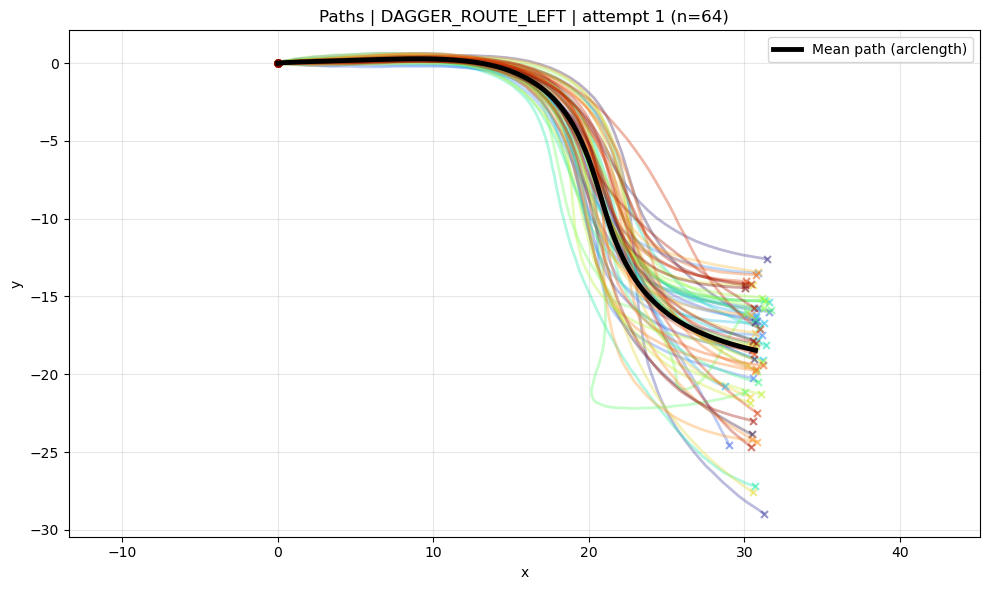

In [26]:
plot_player_paths_all(tracking0,  "DAGGER_ROUTE_LEFT", 1)

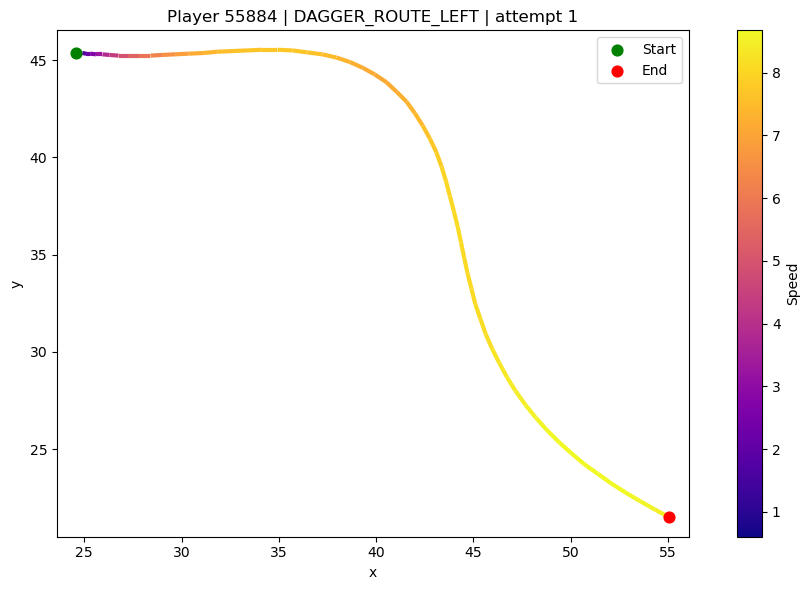

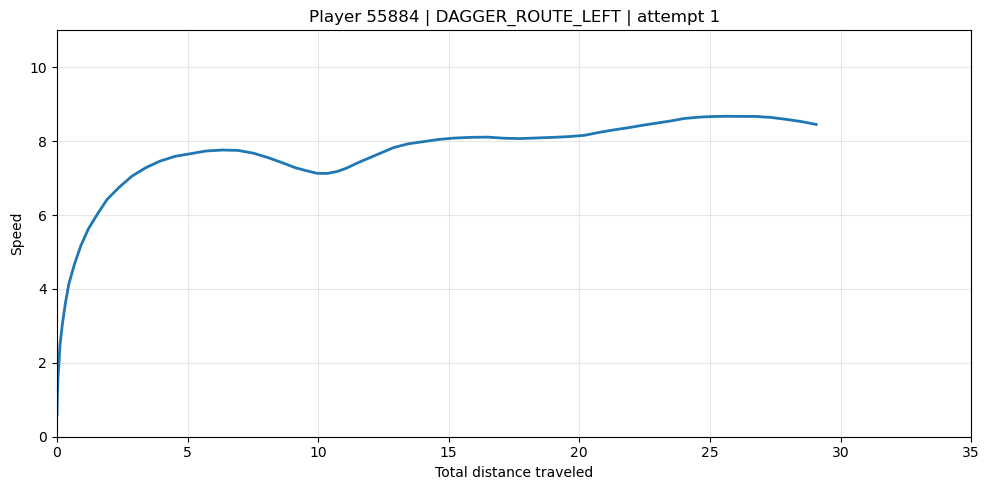

auc: 334.6324119597043
total_dist: 44.09364709409665
avg_speed_over_dist: 7.589129818306764


In [27]:
route_running_plots(tracking, 55884, "DAGGER_ROUTE_LEFT", 1)

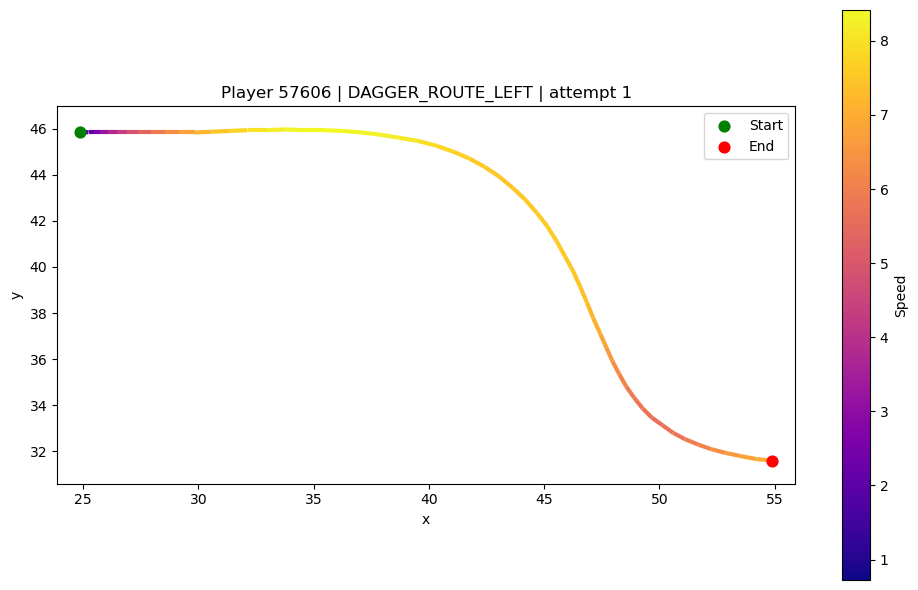

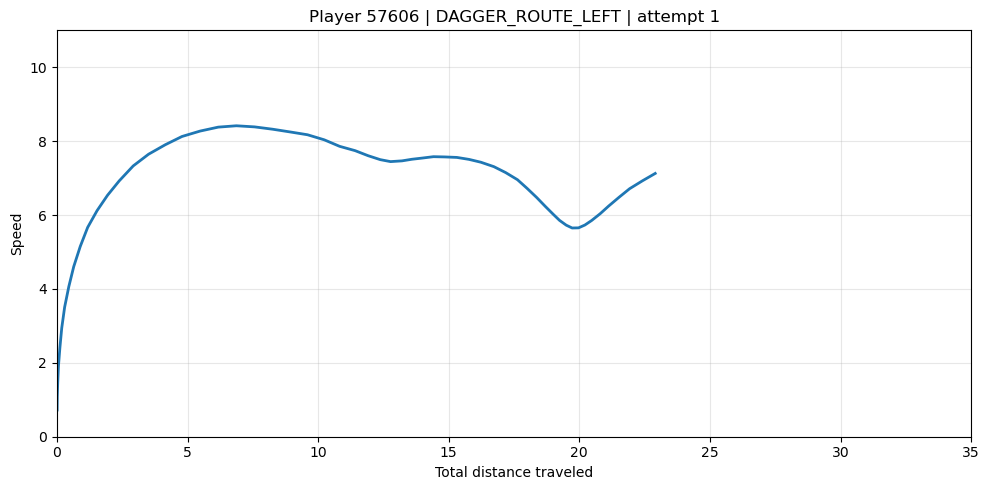

auc: 255.13097716014906
total_dist: 36.74113109877046
avg_speed_over_dist: 6.944015318262398


In [28]:
route_running_plots(tracking, 57606, "DAGGER_ROUTE_LEFT", 1)

normalized_area = area * (1 + abs(current angle - previous angle)/180)
- also do somthing related to when 360 => 1 

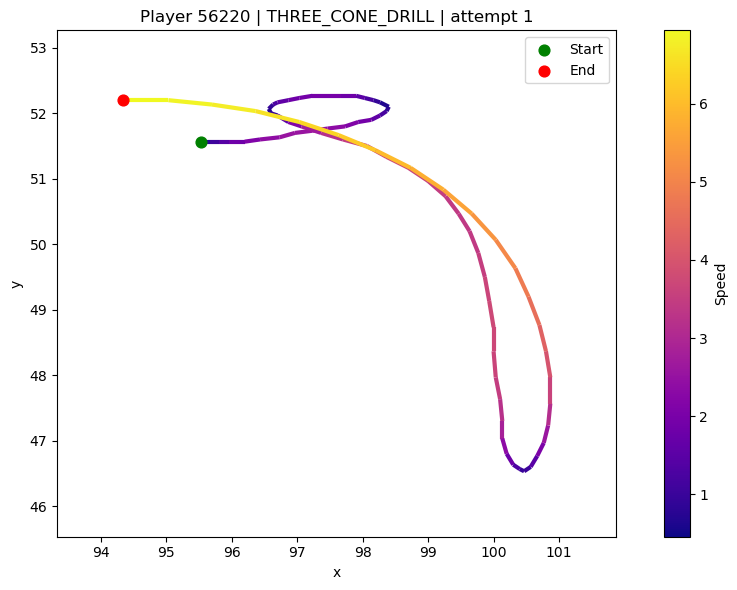

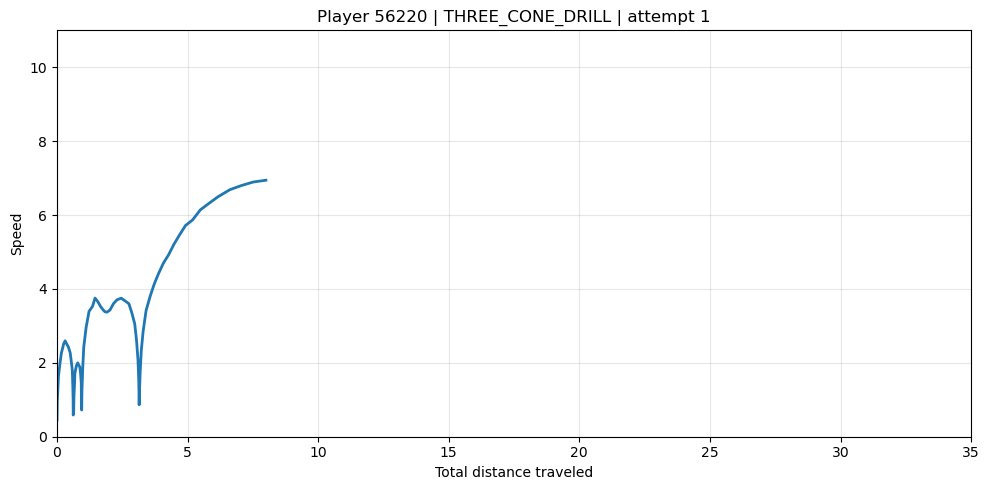

auc: 86.90460934214758
total_dist: 22.570132970844274
avg_speed_over_dist: 3.8504252258686082


In [31]:
route_running_plots(tracking, 56220, "THREE_CONE_DRILL", 1)

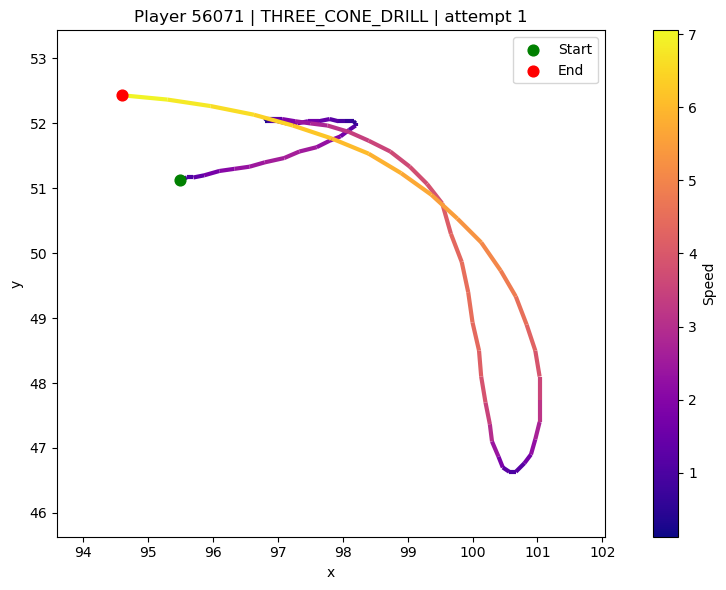

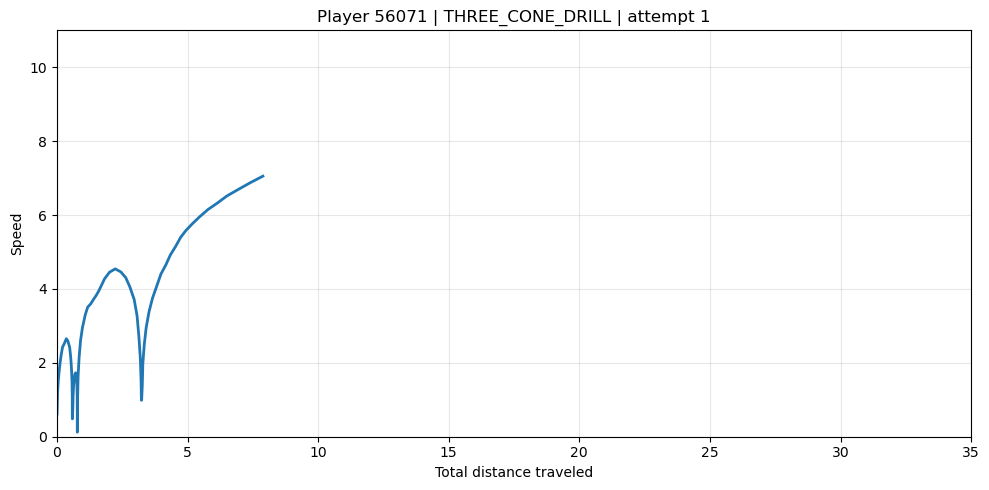

auc: 86.7854557698238
total_dist: 21.903375451709636
avg_speed_over_dist: 3.9621955054899947


In [33]:
route_running_plots(tracking, 56071, "THREE_CONE_DRILL", 1)

In [39]:
MIN_SPEED = 1.0
def run_metrics(p, lag=5):
    p = p.sort_values("time")
    x, y, s = p["x"].to_numpy(), p["y"].to_numpy(), p["s"].to_numpy()

    # distance
    step = np.hypot(np.diff(x), np.diff(y))
    dist = np.r_[0, np.cumsum(step)]
    total_dist = dist[-1]

    # area of each slice (trapezoid): average speed of the two frames * distance of the slice
    slice_area = (s[:-1] + s[1:]) / 2 * step
    area = slice_area.sum()                        # same as trapz(s, dist)

    # turn angle at each slice: heading now minus heading `lag` frames earlier
    heading = np.degrees(np.arctan2(np.diff(y), np.diff(x)))
    turn = np.zeros(len(heading))
    turn[lag:] = np.abs((heading[lag:] - heading[:-lag] + 180) % 360 - 180)

    # heading is unreliable when the player is nearly stopped, so ignore turns there
    slow = (s[:-1] + s[1:]) / 2 < MIN_SPEED
    turn[slow] = 0

    # weight: no turn = 1.0, a 180 degree turn = 2.0 (sharper turn = bigger multiplier)
    weight = 1 + turn / 180
    weighted_area = (slice_area * weight).sum()

    return {"area": area,
            "weighted_area": weighted_area,
            "weighted_area_per_yard": weighted_area / total_dist,
            "total_dist": total_dist}

def score_runs(df, drill_name, attempt=1, area = True):
    d = df[(df["drill_name"] == drill_name) & (df["attempt"] == attempt)]
    m = pd.DataFrame({pid: run_metrics(p, area) for pid, p in d.groupby("nfl_id")}).T
    cols = ["weighted_area_per_yard", "total_dist"]
    z = (m[cols] - m[cols].mean()) / m[cols].std()
    m["score"] = z["weighted_area_per_yard"] - z["total_dist"]
    results =  m.sort_values("score", ascending=False)
    results = results.reset_index().rename(columns={"index": "nfl_id"})
    return results

In [41]:
results = score_runs(tracking, "DAGGER_ROUTE_LEFT")
print(results.head(10))
first_one = set(results["nfl_id"])

   nfl_id        area  weighted_area  weighted_area_per_yard  total_dist  \
0   57205  319.336164     324.647345                8.049341   40.332166   
1   57336  297.343545     301.569689                7.684734   39.242695   
2   55904  261.577178     266.055853                7.237607   36.760195   
3   56015  276.525545     280.995495                7.324537   38.363587   
4   57606  255.130977     259.299233                7.057465   36.741131   
5   57304  253.985033     258.710334                7.004697   36.933836   
6   57155  298.884378     304.209777                7.544540   40.321846   
7   55990  250.182971     254.393468                6.943859   36.635746   
8   55998  282.062927     287.194094                7.329831   39.181542   
9   57263  259.093744     263.836834                7.010024   37.637082   

      score  
0  2.317740  
1  1.929376  
2  1.831672  
3  1.480595  
4  1.468346  
5  1.296445  
6  1.285384  
7  1.270046  
8  1.221369  
9  1.075161  


In [43]:
results = score_runs(tracking, "DAGGER_ROUTE_LEFT", area = False)
print(results.head(10))
second_one = set(results["nfl_id"])

ValueError: operands could not be broadcast together with shapes (63,) (0,) 

In [125]:
print(first_one == second_one)

True
